# Cours de Data Science
<center>
<img src="../images/ds1.png" width=400>
    </center>
<a mailto:madani.a@ucd.ac.ma>madani.a@ucd.ac.ma</a>

## Chapitre 2 — Préparation et nettoyage des données tabulaires

Dans ce chapitre, on va apprendre à préparer un jeu de données avant de l'utiliser en Machine Learning. C'est une étape essentielle : même avec un excellent algorithme, des données mal préparées peuvent conduire à de mauvaises prédictions.

Dans ce chapitre on abordera les éléments suivants :
* **2.1. Comprendre les données tabulaires**
* **2.2. Charger et explorer un dataset**
* **2.3. Identifier et traiter les valeurs manquantes¶**
* **2.4. Détecter et supprimer les doublons**
* **2.5. Comprendre les valeurs aberrantes (outliers)**
* **2.6. Transformer les variables catégorielles en données utilisables**
* **2.7. Mettre les variables numériques à l'échelle**
* **2.8. Séparer les données d'entraînement et de test**
* **2.9. Comprendre la fuite de données (data leakage)**¶
* **2.10. Utiliser un pipeline Scikit-learn**
* **2.11. Préparer un dataset contenant du texte et des nombres**¶

## 2.1 — Comprendre les données tabulaires

Une donnée tabulaire est organisée sous forme d'un tableau constitué de lignes et de colonnes, comme dans Excel.

**Exemple** : un hôtel souhaite analyser ses réservations.

| client | âge | nuits | montant | satisfaction |
| --- | --- | --- | --- | --- |
| C001 | 25 | 2 | 1 200 | Élevée |
| C002 | 34 | 5 | 3 500 | Moyenne |
| C003 | 29 | 1 | 600 | Élevée |
| C004 |  | 3 | 1 800 | Faible |
| C005 | 42 | 4 |  | Moyenne |


*	**Ligne** : un client ou une réservation.
*	**Colonne** : une caractéristique, aussi appelée **variable** ou **feature**.
*	**Valeur** : une information précise, comme l'âge de C001.
*	**Dataset** : l'ensemble du tableau.
*	**Target** : la variable que l'on veut prédire.
*	**Features** : les variables utilisées pour effectuer cette prédiction.

Par exemple, si l'objectif est de prédire la satisfaction du client, satisfaction est la target, tandis que âge, nuits et montant peuvent être des features.

<b><u>Attention</u></b> : il faut éviter d'utiliser une information qui n'est disponible qu'après l'événement que l'on veut prédire. C'est ce qu'on appelle la fuite de données (**data leakage**).

## 2.2 — Charger et explorer un dataset

### Importer les bibliothèques

In [3]:
import pandas as pd
import numpy as np

pandas sert à manipuler des tableaux de données. numpy fournit des outils de calcul et de manipulation de valeurs numériques.

### Créer un dataset d'exemple (à partir d'un dictionnaire)

In [17]:
data = {
    "client": ["C001", "C002", "C003", "C004", "C005"],
    "age": [25, 34, 29, np.nan, 42],
    "nuits": [2, 5, 1, 3, 4],
    "montant": [1200, 3500, 600, 1800, np.nan],
    "satisfaction": [
        "Elevee", "Moyenne", "Elevee",
        "Faible", "Moyenne"
            ]}
df = pd.DataFrame(data)
df

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,NaN,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne



**np.nan** représente une valeur numérique manquante. Dans les données réelles, une cellule vide peut avoir plusieurs significations : 
* information non collectée
* erreur de saisie
* information non applicable.

**Remarque** :<br>
Dans la pratique, au lieu de créer le dataset, on le récupère à partir d'une source externe, comme un fichier CSV, Excel ou autre en utilisant les fonctions **read_csv()**, **read_excel()**, ...

### Examiner les premières lignes

In [10]:
df.head()

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,NaN,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne


head() affiche les cinq premières lignes par défaut.

### Examiner les dernières lignes

In [18]:
df.tail()

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,NaN,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne


### Connaître la taille du dataset

In [19]:
df.shape

(5, 5)

Le résultat est un tuple : (nombre_de_lignes, nombre_de_colonnes). Ici, le tableau contient cinq lignes et cinq colonnes.

### Consulter les noms de colonnes

In [20]:
df.columns

Index(['client', 'age', 'nuits', 'montant', 'satisfaction'], dtype='object')

### Vérifier les types et les valeurs non manquantes

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   client        5 non-null      object 
 1   age           4 non-null      float64
 2   nuits         5 non-null      int64  
 3   montant       4 non-null      float64
 4   satisfaction  5 non-null      object 
dtypes: float64(2), int64(1), object(2)
memory usage: 328.0+ bytes


Cette commande permet notamment de repérer les colonnes qui contiennent des valeurs absentes et de vérifier les types de données.

### Obtenir un résumé statistique simple

In [22]:
df.describe()

,age,nuits,montant
count,4.000000,5.000000,4.0
mean,32.500000,3.000000,1775.0
std,7.325754,1.581139,1250.0
min,25.000000,1.000000,600.0
25%,28.000000,2.000000,1050.0
50%,31.500000,3.000000,1500.0
75%,36.000000,4.000000,2225.0
max,42.000000,5.000000,3500.0


Pour les colonnes **numériques**, Pandas affiche notamment le nombre de valeurs disponibles, la moyenne, l'écart-type, le minimum et le maximum. Vous pouvez utiliser ce résumé sans avoir besoin d'étudier les formules statistiques derrière ces indicateurs.

### Examiner une colonne (Projection sur une seule colonne)

In [23]:
df["montant"]

0    1200.0
1    3500.0
2     600.0
3    1800.0
4       NaN
Name: montant, dtype: float64

### Sélectionner (projection sur) plusieurs colonnes

In [24]:
df[["age", "nuits", "montant"]]

,age,nuits,montant
0,25.0,2,1200.0
1,34.0,5,3500.0
2,29.0,1,600.0
3,NaN,3,1800.0
4,42.0,4,NaN


### Filtrer des lignes

In [25]:
df[df["nuits"] >= 3]

,client,age,nuits,montant,satisfaction
1,C002,34.0,5,3500.0,Moyenne
3,C004,NaN,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne


Cette instruction conserve uniquement les réservations d'au moins trois nuits.

### Trier les données

In [26]:
df.sort_values("montant", ascending=False)

,client,age,nuits,montant,satisfaction
1,C002,34.0,5,3500.0,Moyenne
3,C004,NaN,3,1800.0,Faible
0,C001,25.0,2,1200.0,Elevee
2,C003,29.0,1,600.0,Elevee
4,C005,42.0,4,NaN,Moyenne


Les montants sont triés du plus élevé au plus faible. Les valeurs manquantes peuvent apparaître à la fin du tableau.

## 2.3 — Identifier et traiter les valeurs manquantes

Les valeurs manquantes sont fréquentes dans les datasets. On les appelle aussi **missing values** ou valeurs nulles.

### Il existe plusieurs stratégies pour les traiter :

*	Supprimer les lignes incomplètes.
*	Supprimer une colonne si elle est trop incomplète et peu utile.
*	Remplacer les valeurs manquantes par une valeur appropriée.
*	Ajouter une variable indiquant qu'une valeur était manquante, lorsque cette information peut être utile.

Il n'existe pas de solution universelle : le choix dépend du contexte et de la signification des données absentes.

### Compter les valeurs manquantes par colonne

**df.isna()** indique si une valeur est null (True) ou non nulle (False)

In [11]:
df.isna()

,client,age,nuits,montant,satisfaction
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,True,False,False,False
4,False,False,False,True,False


Pour compter le nombre de valeur manquantes pour chaque colonne, on utilise **df.isna().sum()**

In [28]:
df.isna().sum()

client          0
age             1
nuits           0
montant         1
satisfaction    0
dtype: int64

**Explication** :

* age : 1 valeur manquante.
* montant : 1 valeur manquante.
* Les autres colonnes : aucune valeur manquante.

### Calculer le pourcentage de valeurs manquantes

In [29]:
(df.isna().mean() * 100).round(2)

client           0.0
age             20.0
nuits            0.0
montant         20.0
satisfaction     0.0
dtype: float64

Cela permet de repérer les colonnes fortement incomplètes.

### Afficher uniquement les lignes incomplètes

In [30]:
df[df.isna().any(axis=1)]

,client,age,nuits,montant,satisfaction
3,C004,NaN,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne


axis=1 signifie ici qu'on examine les colonnes de chaque ligne pour détecter la présence d'au moins une valeur manquante.

### Supprimer les lignes incomplètes

In [18]:
df_sans_manquants = df.dropna()
df_sans_manquants

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee


Cette méthode est simple, mais elle peut supprimer beaucoup d'informations. Elle est à utiliser lorsque la suppression est justifiée, et non systématiquement.

### Supprimer les lignes où une colonne précise est manquante

In [32]:
df.dropna(subset=["age"])

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
4,C005,42.0,4,NaN,Moyenne


Ici, seules les lignes avec âge renseigné sont conservées.

### Remplacer les âges manquants par la médiane

In [33]:
df_mediane = df.copy()
mediane_age = df_mediane["age"].median()
print("median age:", mediane_age)
df_mediane["age"] = df_mediane["age"].fillna(mediane_age)
df_mediane

median age: 31.5


,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,31.5,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne


La médiane est la valeur centrale lorsque les données sont classées. Elle est souvent plus robuste que la moyenne face à des valeurs extrêmes.

**Remarque** :
* df_copy = df : Cette instruction créée un deuxième nom pour le même objet
* df_copy = df.copy() : cette instruction créée un nouveau DataFrame indépendant.

### Remplacer les montants manquants par la médiane

In [34]:
df_mediane["montant"] = df_mediane["montant"].fillna(df_mediane["montant"].median())
df_mediane

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,31.5,3,1800.0,Faible
4,C005,42.0,4,1500.0,Moyenne


Dans un véritable projet, il faut vérifier que cette stratégie est cohérente : un montant manquant ne signifie pas toujours un montant proche du montant médian.

### Remplacer une valeur manquante par une constante

In [35]:
df_constante = df.copy()
df_constante["age"] = df_constante["age"].fillna(0)
df_constante

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,0.0,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne


Techniquement, c'est possible, mais zéro n'est pas toujours une valeur pertinente. Un âge de zéro pourrait être interprété par l'algorithme comme un véritable âge. Pour un âge inconnu, la médiane ou une catégorie explicite peut être plus adaptée.

### Ajouter un indicateur de valeur manquante

In [36]:
df_indicateur = df.copy()
#df_indicateur["age_manquant"] = df_indicateur["age"].isna()
df_indicateur["age_manquant"] = df_indicateur["age"].isna().astype(int)
df_indicateur

,client,age,nuits,montant,satisfaction,age_manquant
0,C001,25.0,2,1200.0,Elevee,0
1,C002,34.0,5,3500.0,Moyenne,0
2,C003,29.0,1,600.0,Elevee,0
3,C004,NaN,3,1800.0,Faible,1
4,C005,42.0,4,NaN,Moyenne,0


La nouvelle colonne vaut 1 lorsque l'âge était absent et 0 sinon. Cet indicateur peut parfois aider le modèle à exploiter le fait que l'information n'a pas été renseignée.

### À retenir

| Méthode | Quand l'envisager ? |
| --- | --- |
| dropna() | Lorsque supprimer les lignes est acceptable |
| Remplacement par la médiane | Pour certaines variables numériques |
| Remplacement par le mode | Pour certaines variables catégorielles |
| Valeur constante | Lorsque cette valeur a un sens métier |
| Indicateur de valeur manquante | Lorsque l'absence d'information peut être informative |


## 2.4 — Détecter et supprimer les doublons

Un doublon apparaît lorsqu'une ligne est répétée ou lorsqu'un enregistrement est présent plusieurs fois. <br>
**<u>Attention</u>** : deux clients peuvent légitimement avoir exactement les mêmes caractéristiques. Une ligne identique n'est donc pas forcément une erreur.

### Créer un dataset avec un doublon

In [37]:
df_doublons = pd.concat([df, df.iloc[[0]]],ignore_index=True)
# df_doublons = pd.concat([df, df.iloc[[0,1]]],ignore_index=True)
df_doublons

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,NaN,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne
5,C001,25.0,2,1200.0,Elevee


#### Rappels : 
1. **Les principales utilisations de iloc**

| Expression | Signification |
| --- | --- |
| df.iloc[0] | Première ligne| 
| df.iloc[1] | 	Deuxième ligne| 
| df.iloc[-1]	| Dernière ligne| 
| df.iloc[:3] | 	Trois premières lignes| 
| df.iloc[0, 1]	| Valeur de la première ligne, deuxième colonne | 
| df.iloc[:, 0]	| Toutes les lignes de la première colonne| 
| df.iloc[0:2, 0:2]	| Deux premières lignes et deux premières colonnes| 

2. **Différence entre iloc et loc** :
- iloc : sélection par position numérique.
- loc : sélection par étiquette d'index.

### Afficher les lignes dupliquées

In [38]:
df_doublons.duplicated()

0    False
1    False
2    False
3    False
4    False
5     True
dtype: bool

### Compter les lignes dupliquées

In [39]:
df_doublons.duplicated().sum() #print(df_doublons.duplicated().sum())

np.int64(1)

### Afficher les doublons

In [83]:
df_doublons[df_doublons.duplicated(keep=False)]

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
5,C001,25.0,2,1200.0,Elevee


Le paramètre keep peut prendre :
* **keep='first'** : La première occurrence est considérée comme unique. Les occurrences suivantes sont considérées comme des doublons (valeur par défaut)
* **keep='last'** : La dernière occurrence est conservée comme unique. Les occurrences précédentes sont considérées comme des doublons.
* **keep='False'**: toutes les occurrences des lignes dupliquées sont signalées.

### Supprimer les doublons

In [41]:
df_nettoye = df_doublons.drop_duplicates()
df_nettoye

,client,age,nuits,montant,satisfaction
0,C001,25.0,2,1200.0,Elevee
1,C002,34.0,5,3500.0,Moyenne
2,C003,29.0,1,600.0,Elevee
3,C004,NaN,3,1800.0,Faible
4,C005,42.0,4,NaN,Moyenne


### Détecter les doublons selon une clé métier

In [42]:
reservations = pd.DataFrame({
    "reservation_id": [101, 102, 103, 103],
    "client": ["A", "B", "C", "C"],
    "montant": [900, 1200, 1500, 1500]})
reservations

,reservation_id,client,montant
0,101,A,900
1,102,B,1200
2,103,C,1500
3,103,C,1500


In [43]:
reservations.duplicated(subset=["reservation_id"])

0    False
1    False
2    False
3     True
dtype: bool

Dans ce cas, on vérifie si l'identifiant de réservation est répété. C'est souvent plus pertinent que de comparer toutes les colonnes.

### Conserver une seule occurrence par identifiant

In [44]:
reservations_uniques = reservations.drop_duplicates(
    subset=["reservation_id"],
    keep="first")
reservations_uniques

,reservation_id,client,montant
0,101,A,900
1,102,B,1200
2,103,C,1500


<u>**Attention**</u> : conserver la première occurrence est une règle technique, pas forcément la meilleure règle métier. Si les deux enregistrements diffèrent, il faut décider lequel est fiable.

## 2.5 Comprendre les valeurs aberrantes (outliers)

Une valeur aberrante est une observation qui s'éloigne fortement des autres.

**Exemple** : les montants de réservation sont généralement compris entre 500 et 5 000 MAD, mais une réservation apparaît avec un montant de 200 000 MAD.

### Trois possibilités existent :

1.	Erreur de saisie : le montant devrait être 2 000 MAD.
2.	Observation rare mais réelle : il s'agit d'une réservation exceptionnelle.
3.	Cas particulier : le montant correspond à plusieurs chambres ou à un séjour de longue durée.

Il ne faut donc pas supprimer automatiquement toutes les valeurs extrêmes.

### Créer un dataset contenant une valeur extrême

In [84]:
df_montants = pd.DataFrame({
    "montant": [10, 20, 22, 25, 27, 28, 30, 32, 35, 100]})
df_montants

,montant
0,10
1,20
2,22
3,25
4,27
5,28
6,30
7,32
8,35
9,100


### Examiner les montants

In [85]:
df_montants["montant"].describe()

count     10.000000
mean      32.900000
std       24.601039
min       10.000000
25%       22.750000
50%       27.500000
75%       31.500000
max      100.000000
Name: montant, dtype: float64

Le maximum (le minimum) est très supérieur (inférieur) aux autres valeurs. Cela mérite une investigation.

### Visualiser les valeurs avec une boîte à moustaches

Une boîte à moustaches (Boxplot en anglais) est un graphique statistique qui permet de visualiser la distribution d'une variable numérique, sa dispersion, sa médiane et ses valeurs aberrantes (outliers).

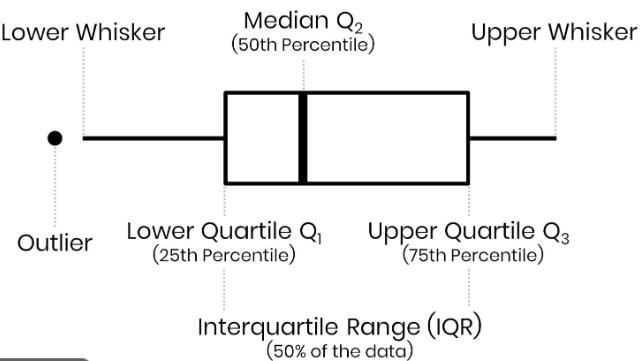

Les éléments principaux :
- Q1 (1er quartile) : 25 % des valeurs sont inférieures ou égales à Q1.
- Médiane (Q2) : 50 % des valeurs sont inférieures ou égales à la médiane.
- Q3 (3e quartile) : 75 % des valeurs sont inférieures ou égales à Q3.
- Boîte : représente l'intervalle entre Q1 et Q3, qui contient les 50 % centraux des données.
- Moustaches : s'étendent généralement jusqu'aux dernières valeurs situées dans les limites définies par la méthode du boxplot.
- Points isolés : représentent généralement les valeurs aberrantes potentielles.

L'écart interquartile est (_**Interquartile Range**_):
\begin{aligned}
IQR = Q3-Q1
\end{aligned}


Les limites habituelles pour détecter les valeurs aberrantes sont :
\begin{aligned}
L_{\min} &= Q1-1.5 \times IQR\\
L_{\max} &= Q3+1.5 \times IQR
\end{aligned}


Une valeur située en dehors de ces limites est considérée comme une valeur aberrante potentielle, pas nécessairement comme une erreur.

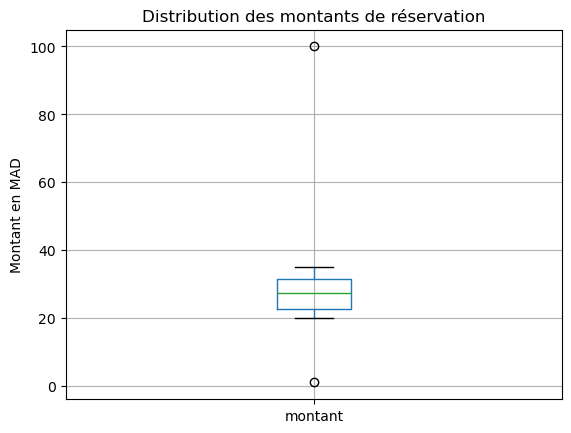

In [47]:
import matplotlib.pyplot as plt
df_montants.boxplot(column="montant")
plt.title("Distribution des montants de réservation")
plt.ylabel("Montant en MAD")
plt.show()

Ce graphique (boîte à moustaches, ou boxplot), permet de représenter la distribution de la colonne Age et permet de repérer une éventuelle valeur aberrante, comme 60 dans cet exemple.

### Détecter des valeurs extrêmes avec la règle de l'IQR

L'IQR, ou intervalle interquartile, est une méthode classique de détection des valeurs éloignées. Ici, on l'utilise comme un outil de repérage, pas comme une preuve qu'une observation est erronée.

In [48]:
q1 = df_montants["montant"].quantile(0.25)
q3 = df_montants["montant"].quantile(0.75)
iqr = q3 - q1
borne_basse = q1 - 1.5 * iqr
borne_haute = q3 + 1.5 * iqr
outliers = df_montants[
    (df_montants["montant"] < borne_basse)
    | (df_montants["montant"] > borne_haute)]
outliers

,montant
0,1
9,100


Vous n'avez besoin de retenir la formule par cœur dès maintenant. L'essentiel est de comprendre que la méthode construit des bornes à partir de la distribution des données.

### Compter les valeurs extrêmes détectées

In [49]:
len(outliers)

2

### Filtrer temporairement les valeurs détectées

In [50]:
df_filtre = df_montants[
(df_montants["montant"] >= borne_basse)
& (df_montants["montant"] <= borne_haute)]
df_filtre

,montant
1,20
2,22
3,25
4,27
5,28
6,30
7,32
8,35


Cette cellule montre comment filtrer les observations détectées. Ne le faites pas automatiquement sur un dataset réel : une réservation exceptionnelle peut être parfaitement légitime.

### Comparer les données avant et après le filtrage

In [51]:
print("Nombre de lignes initial :", len(df_montants))
print("Nombre de lignes filtré :", len(df_filtre))

Nombre de lignes initial : 10
Nombre de lignes filtré : 8


Dans un projet sérieux, il faut documenter les observations exclues et justifier chaque décision.

## 2.6 — Transformer les variables catégorielles en données utilisables

Les algorithmes de Machine Learning ont souvent besoin de variables numériques. Or, les datasets contiennent fréquemment des catégories textuelles :

*	Type de chambre : standard, de luxe, suite.
*	Mode de paiement : espèces, carte, virement.
*	Satisfaction : faible, moyenne, élevée.
*	Ville : Casablanca, Rabat, Marrakech.

Il faut transformer ces catégories de manière adaptée.

### Créer un dataset catégoriel

In [86]:
df_categories = pd.DataFrame({
    "client": ["A", "B", "C", "D", "E"],
    "type_chambre": ["Standard", "Deluxe", "Suite", "Standard", "Deluxe"],
    "satisfaction": ["Faible", "Moyenne", "Elevee", "Elevee", "Faible"]})
df_categories

,client,type_chambre,satisfaction
0,A,Standard,Faible
1,B,Deluxe,Moyenne
2,C,Suite,Elevee
3,D,Standard,Elevee
4,E,Deluxe,Faible


### Compter les catégories

In [89]:
df_categories["type_chambre"].value_counts()
#df_categories.groupby('type_chambre').size()

type_chambre
Standard    2
Deluxe      2
Suite       1
Name: count, dtype: int64

### Examiner les catégories possibles

In [54]:
df_categories["type_chambre"].unique()

array(['Standard', 'Deluxe', 'Suite'], dtype=object)

### Encoder une variable binaire

Pour une variable à deux modalités, on peut utiliser un encodage binaire. Exemple : oui devient 1 et non devient 0.

In [94]:
df_binaire = pd.DataFrame({
    "client": ["A", "B", "C", "D"],
    "newsletter": ["oui", "non", "oui", "non"]})
df_binaire

,client,newsletter
0,A,oui
1,B,non
2,C,oui
3,D,non


In [95]:
df_binaire["newsletter_code"] = (df_binaire["newsletter"].map({"non": 0, "oui": 1}))
df_binaire

,client,newsletter,newsletter_code
0,A,oui,1
1,B,non,0
2,C,oui,1
3,D,non,0


Si une valeur n'est pas prévue dans le dictionnaire, map() renverra une valeur manquante. Il faut donc vérifier les modalités avant l'encodage.

### Utiliser le One-Hot Encoding

Le One-Hot Encoding crée une colonne par catégorie. Il évite de donner artificiellement un ordre numérique aux catégories nominales.

In [97]:
df_categories

,client,type_chambre,satisfaction
0,A,Standard,Faible
1,B,Deluxe,Moyenne
2,C,Suite,Elevee
3,D,Standard,Elevee
4,E,Deluxe,Faible


In [96]:
pd.get_dummies(df_categories, columns=["type_chambre"], dtype=int)

,client,satisfaction,type_chambre_Deluxe,type_chambre_Standard,type_chambre_Suite
0,A,Faible,0,1,0
1,B,Moyenne,1,0,0
2,C,Elevee,0,0,1
3,D,Elevee,0,1,0
4,E,Faible,1,0,0


Par exemple, une réservation en chambre Deluxe aura 1 dans la colonne type_chambre_Deluxe et 0 dans les autres colonnes de type de chambre.

### Encoder plusieurs variables catégorielles

In [98]:
df_encode = pd.get_dummies(df_categories, columns=["type_chambre", "satisfaction"], dtype=int)
df_encode

,client,type_chambre_Deluxe,type_chambre_Standard,type_chambre_Suite,satisfaction_Elevee,satisfaction_Faible,satisfaction_Moyenne
0,A,0,1,0,0,1,0
1,B,1,0,0,0,0,1
2,C,0,0,1,1,0,0
3,D,0,1,0,1,0,0
4,E,1,0,0,0,1,0


### Encoder une variable ordinale

Une variable ordinale possède un ordre naturel. C'est le cas de la satisfaction : faible, moyenne, élevée.

In [58]:
ordre_satisfaction = {"Faible": 0, "Moyenne": 1, "Elevee": 2}
df_ordinal = df_categories.copy()
df_ordinal["satisfaction_code"] = (df_ordinal["satisfaction"].map(ordre_satisfaction))
df_ordinal

,client,type_chambre,satisfaction,satisfaction_code
0,A,Standard,Faible,0
1,B,Deluxe,Moyenne,1
2,C,Suite,Elevee,2
3,D,Standard,Elevee,2
4,E,Deluxe,Faible,0


Cet encodage est pertinent parce que l'ordre existe réellement. En revanche, les écarts entre les codes ne signifient pas nécessairement que les différences de satisfaction sont quantitativement égales.

### Vérifier si l'encodage a créé des valeurs manquantes

In [59]:
df_ordinal["satisfaction_code"].isna().sum()

np.int64(0)

Un résultat non nul peut révéler une faute de frappe, une modalité inconnue ou une catégorie oubliée.

### Examiner les types de données après encodage

In [60]:
df_encode.dtypes

client                   object
type_chambre_Deluxe       int64
type_chambre_Standard     int64
type_chambre_Suite        int64
satisfaction_Elevee       int64
satisfaction_Faible       int64
satisfaction_Moyenne      int64
dtype: object

Après l'encodage, les colonnes créées sont numériques et peuvent servir de features pour de nombreux algorithmes.

## 2.7 — Mettre les variables numériques à l'échelle

Les colonnes numériques peuvent utiliser des unités très différentes.

### Exemple :

- Âge : entre 18 et 80.<br>
- Nombre de nuits : entre 1 et 30.<br>
- Montant : entre 500 et 50 000 MAD.

Certains algorithmes sont sensibles à ces différences d'échelle. La standardisation ou la normalisation peut alors être utile.

### Créer des variables d'échelles différentes

In [99]:
df_echelles = pd.DataFrame({
    "age": [22, 35, 48, 29, 41],
    "nuits": [1, 3, 7, 2, 5],
    "montant": [500, 1800, 7000, 1200, 4500]})
df_echelles

,age,nuits,montant
0,22,1,500
1,35,3,1800
2,48,7,7000
3,29,2,1200
4,41,5,4500


### Observer les échelles

In [100]:
df_echelles.describe()

,age,nuits,montant
count,5.000000,5.000000,5.000000
mean,35.000000,3.600000,3000.000000
std,10.124228,2.408319,2700.925767
min,22.000000,1.000000,500.000000
25%,29.000000,2.000000,1200.000000
50%,35.000000,3.000000,1800.000000
75%,41.000000,5.000000,4500.000000
max,48.000000,7.000000,7000.000000


Le montant est exprimé sur une échelle beaucoup plus grande que l'âge ou le nombre de nuits.

### Standardiser avec StandardScaler

In [101]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
colonnes = ["age", "nuits", "montant"]
donnees_standardisees = scaler.fit_transform(df_echelles[colonnes])
df_standardise = pd.DataFrame(donnees_standardisees, columns=colonnes)
df_standardise

,age,nuits,montant
0,-1.435610,-1.207020,-1.034862
1,0.000000,-0.278543,-0.496734
2,1.435610,1.578410,1.655779
3,-0.662589,-0.742781,-0.745101
4,0.662589,0.649934,0.620917


La standardisation transforme les colonnes pour les centrer autour de zéro et les exprimer selon une échelle liée à leur dispersion. Les résultats peuvent être négatifs : cela signifie simplement qu'une observation se situe sous le niveau moyen de la colonne transformée.

### Comparer les données initiales et transformées

In [102]:
print("Données initiales :")
df_echelles.head()

Données initiales :


,age,nuits,montant
0,22,1,500
1,35,3,1800
2,48,7,7000
3,29,2,1200
4,41,5,4500


In [103]:
print("\nDonnées standardisées :")
df_standardise.head()


Données standardisées :


,age,nuits,montant
0,-1.435610,-1.207020,-1.034862
1,0.000000,-0.278543,-0.496734
2,1.435610,1.578410,1.655779
3,-0.662589,-0.742781,-0.745101
4,0.662589,0.649934,0.620917


Les valeurs transformées ne sont plus exprimées directement en années, en nuits ou en dirhams. Il faut conserver les données originales pour les interpréter.

### Normaliser avec MinMaxScaler

Une autre méthode consiste à ramener chaque colonne dans un intervalle, généralement de 0 à 1.

In [104]:
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler()
donnees_normalisees = minmax.fit_transform(df_echelles[colonnes])
df_normalise = pd.DataFrame(donnees_normalisees, columns=colonnes)
df_normalise

,age,nuits,montant
0,0.000000,0.000000,0.000000
1,0.500000,0.333333,0.200000
2,1.000000,1.000000,1.000000
3,0.269231,0.166667,0.107692
4,0.730769,0.666667,0.615385


La normalisation Min-Max dépend des valeurs minimales et maximales observées. Une valeur extrême peut donc modifier fortement l'échelle obtenue.

### Vérifier les minima et maxima après normalisation

In [66]:
print(df_normalise.min())
print(df_normalise.max())

age        0.0
nuits      0.0
montant    0.0
dtype: float64
age        1.0
nuits      1.0
montant    1.0
dtype: float64


Pour ce dataset et les données utilisées pour ajuster le transformateur, les minima doivent être égaux à 0 et les maxima à 1.

### Choisir une méthode d'échelle

| Méthode | Idée générale | Cas d'usage fréquent |
| --- | --- | --- |
| StandardScaler | Centrer et standardiser les variables | Régression logistique, SVM, KNN |
| MinMaxScaler | Ramener les valeurs dans un intervalle | Certains réseaux de neurones, KNN |
| Pas de mise à l'échelle | Garder les unités originales | Arbres de décision et forêts aléatoires, généralement |


Ces indications sont des repères, pas des règles absolues. La mise à l'échelle n'est pas toujours nécessaire et dépend de l'algorithme ainsi que des données.

## 2.8 — Séparer les données d'entraînement et de test

C'est une étape fondamentale du Machine Learning.

Imaginons que tu veuilles prédire si un client sera satisfait d'un séjour. Tu dois apprendre au modèle à partir d'une partie des données, puis vérifier ses performances sur des données qu'il n'a pas utilisées pendant l'entraînement.

* Training set : données d'entraînement, utilisées pour apprendre.
* Test set : données réservées à l'évaluation finale.
* Validation set : données parfois utilisées pour comparer les modèles et régler leurs paramètres.

Une séparation courante consiste à utiliser 80 % des données pour l'entraînement et 20 % pour le test. Ce n'est toutefois pas une règle universelle.

### Créer un dataset adapté à la classification

In [67]:
df_clients = pd.DataFrame({
    "age": [22, 35, 48, 29, 41, 26, 54, 33, 38, 45],
    "nuits": [1, 3, 7, 2, 5, 2, 6, 4, 3, 5],
    "montant": [
        500, 1800, 7000, 1200, 4500,
        900, 6200, 2800, 2100, 5100
        ],
    "satisfait": [
        "non", "oui", "oui", "non", "oui",
        "non", "oui", "oui", "non", "oui"
            ]})
df_clients

,age,nuits,montant,satisfait
0,22,1,500,non
1,35,3,1800,oui
2,48,7,7000,oui
3,29,2,1200,non
4,41,5,4500,oui
5,26,2,900,non
6,54,6,6200,oui
7,33,4,2800,oui
8,38,3,2100,non
9,45,5,5100,oui


Il s'agit d'un dataset pédagogique fictif, conçu pour illustrer les opérations. Il ne représente pas une étude réelle de satisfaction.

### Définir les features et la target

In [68]:
X = df_clients[["age", "nuits", "montant"]]
y = df_clients["satisfait"]

X contient les informations d'entrée. y contient la réponse que le modèle devra apprendre à prédire.

### Effectuer la séparation

In [69]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)    


test_size=0.2 réserve 20 % des lignes au test. random_state=42 permet de reproduire la même séparation lorsque le code est exécuté dans les mêmes conditions.

### Vérifier la taille des ensembles

In [70]:
print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (8, 3)
Test : (2, 3)


Avec dix lignes au départ, on obtient huit lignes d'entraînement et deux lignes de test.

### Vérifier la distribution des classes

In [71]:
print("Entraînement :")
print(y_train.value_counts())
print("\nTest :")
print(y_test.value_counts())

Entraînement :
satisfait
oui    5
non    3
Name: count, dtype: int64

Test :
satisfait
non    1
oui    1
Name: count, dtype: int64


Dans un dataset réel, la séparation peut laisser trop peu d'exemples d'une classe dans le test. Une séparation stratifiée peut être utile lorsque l'on veut préserver approximativement les proportions des classes.

### Utiliser une séparation stratifiée

In [72]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Cette option est surtout utile pour les problèmes de classification. Elle nécessite suffisamment d'exemples dans chaque classe pour effectuer la séparation.

## 2.9 — Comprendre la fuite de données (data leakage)

La fuite de données se produit lorsqu'une information qui ne devrait pas être accessible au modèle pendant l'apprentissage influence son entraînement ou son évaluation.

Exemple : tu veux prédire la satisfaction à l'arrivée du client, mais tu utilises une colonne **remboursement_apres_reclamation**, qui n'est renseignée qu'après le séjour.

Le modèle peut obtenir de très bons résultats pendant l'évaluation sans être réellement utile au moment de la prédiction.

Une autre erreur fréquente consiste à calculer la moyenne, la médiane ou les paramètres de standardisation sur l'ensemble du dataset avant de le séparer. Les données de test influencent alors indirectement la préparation du modèle.

### Mauvaise pratique : ajuster le scaler avant la séparation

In [73]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()# Mauvaise pratique pédagogique : à ne pas reproduire
X_scaled = scaler.fit_transform(X)
X_train_bad, X_test_bad, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

Le problème est que **fit_transform(X)** apprend les paramètres de transformation à partir de toutes les lignes, y compris celles qui seront ensuite réservées au test.

### Bonne pratique : ajuster le scaler sur l'entraînement uniquement

In [74]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### La différence est importante :

* **fit_transform()** apprend les paramètres sur l'entraînement puis transforme les données.
* **transform()** applique les paramètres déjà appris, sans les recalculer sur le test.

Cette règle s'applique aussi aux imputations et aux encodages qui apprennent des informations à partir du dataset.

## 2.10 — Utiliser un pipeline Scikit-learn

Un pipeline regroupe plusieurs étapes de préparation et d'apprentissage dans un seul objet. Il permet de rendre le code plus cohérent et de réduire le risque de fuite de données.

### Importer les outils nécessaires

In [75]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

Nous utiliserons ici une régression logistique, un algorithme classique de classification. Malgré son nom, il peut servir à prédire une catégorie, par exemple oui ou non.

### Construire un pipeline simple

In [76]:
pipeline = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler()),
    ("modele", LogisticRegression())])

### Les étapes s'exécutent dans l'ordre :

1. Remplacer les valeurs numériques manquantes par la médiane calculée sur les données d'entraînement.
2. Standardiser les variables numériques.
3. Entraîner le modèle de classification.

### Entraîner le pipeline

In [77]:
pipeline.fit(X_train, y_train)

,steps,"[('imputation', ...), ('standardisation', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


La méthode fit() entraîne l'ensemble des étapes du pipeline à partir des données d'entraînement.

### Effectuer des prédictions

In [78]:
predictions = pipeline.predict(X_test)
predictions

array(['non', 'oui'], dtype=object)

Le modèle produit une classe prédite pour chaque ligne de test.

### Comparer les prédictions aux vraies réponses

In [79]:
comparaison = pd.DataFrame({
    "reponse_reelle": y_test.values,
    "prediction": predictions})
comparaison

,reponse_reelle,prediction
0,non,non
1,oui,oui


Cette comparaison permet de voir les cas où le modèle se trompe. Avec seulement dix observations fictives, il ne faut cependant tirer aucune conclusion sérieuse sur ses performances.

### Évaluer le modèle avec l'accuracy

In [80]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, predictions)
print("Accuracy :", accuracy)

Accuracy : 1.0


L'accuracy est la proportion de prédictions correctes parmi les prédictions évaluées. Par exemple, une accuracy de 0.80 correspond à 80 % de prédictions correctes.

***Attention*** : une bonne accuracy ne garantit pas un bon modèle. Si 95 % des clients appartiennent à une seule classe, un modèle qui prédit toujours cette classe peut atteindre 95 % d'accuracy sans identifier correctement les clients de l'autre classe.

## 2.11 — Préparer un dataset contenant du texte et des nombres

Dans la réalité, les données sont rarement composées uniquement de nombres. On peut avoir l'âge, le montant, la ville, le type de chambre ou le canal de réservation dans un même tableau.

Il faut alors appliquer des transformations différentes selon le type de colonne.

### Créer un dataset mixte

In [81]:
df_mixte = pd.DataFrame({
    "age": [25, 34, np.nan, 42, 29, 38, 31, 46, 27, 35],
    "nuits": [2, 5, 3, 4, 1, 6, 2, 5, 3, 4],
    "montant": [1200, 3500, 1800, 4200, 600,
                5000, 1400, 4700, 2100, 3000],
    "type_chambre": [
        "Standard", "Deluxe", "Standard", "Suite", "Standard",
        "Deluxe", "Standard", "Suite", "Deluxe", "Standard"
            ],
    "canal": [
        "Site", "Agence", "Site", "Application", "Agence",
        "Application", "Site", "Agence", "Application", "Site"
            ],
    "satisfait": [
        "oui", "oui", "non", "oui", "non",
        "oui", "non", "oui", "oui", "non"
            ]})
df_mixte

,age,nuits,montant,type_chambre,canal,satisfait
0,25.0,2,1200,Standard,Site,oui
1,34.0,5,3500,Deluxe,Agence,oui
2,NaN,3,1800,Standard,Site,non
3,42.0,4,4200,Suite,Application,oui
4,29.0,1,600,Standard,Agence,non
5,38.0,6,5000,Deluxe,Application,oui
6,31.0,2,1400,Standard,Site,non
7,46.0,5,4700,Suite,Agence,oui
8,27.0,3,2100,Deluxe,Application,oui
9,35.0,4,3000,Standard,Site,non
